# Cálculo Numérico — Lista de Exercícios: Método de Gauss–Seidel

**Aluno:** Felipe Pinto Zanata — UNIFESP · Profa. Raquel Lobosco

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Z4nata/CalculoNumerico/blob/main/Atividade_6.ipynb)

Sistema resolvido:

$$
\begin{cases}
10x - y + 2z = 6\\
-x + 11y - z = 22\\
2x - y + 10z = -10
\end{cases}
$$

Aproximação inicial $\mathbf{x}^{(0)} = (0, 0, 0)$ e critério de parada
$\|\mathbf{x}^{(k)} - \mathbf{x}^{(k-1)}\|_\infty < 10^{-5}$.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1. Forma matricial $A\mathbf{x} = \mathbf{b}$

In [2]:
A = np.array([[10, -1,  2],
              [-1, 11, -1],
              [ 2, -1, 10]], dtype=float)
b = np.array([6, 22, -10], dtype=float)
x0 = np.zeros(3)

## 2. Dominância diagonal por linhas

Para cada linha $i$, verifica se $|a_{ii}| > \sum_{j \ne i} |a_{ij}|$. Essa propriedade é condição
suficiente para o método de Gauss–Seidel convergir, qualquer que seja $\mathbf{x}^{(0)}$.

In [3]:
for i in range(len(A)):
    diagonal = abs(A[i, i])
    fora_da_diagonal = np.sum(np.abs(A[i])) - diagonal
    print(f"Linha {i + 1}: |a_{i + 1}{i + 1}| = {diagonal:g} > {fora_da_diagonal:g} ? {diagonal > fora_da_diagonal}")

Linha 1: |a_11| = 10 > 3 ? True
Linha 2: |a_22| = 11 > 2 ? True
Linha 3: |a_33| = 10 > 3 ? True


## 3. Fórmulas iterativas

Isolando $x$ na 1ª equação, $y$ na 2ª e $z$ na 3ª:

$$
\begin{aligned}
x^{(k)} &= \frac{6 + y^{(k-1)} - 2z^{(k-1)}}{10}\\
y^{(k)} &= \frac{22 + x^{(k)} + z^{(k-1)}}{11}\\
z^{(k)} &= \frac{-10 - 2x^{(k)} + y^{(k)}}{10}
\end{aligned}
$$

- $x^{(k)}$ usa $y^{(k-1)}$ e $z^{(k-1)}$, ainda da iteração anterior;
- $y^{(k)}$ já usa o $x^{(k)}$ recém-calculado e o $z^{(k-1)}$ antigo;
- $z^{(k)}$ usa $x^{(k)}$ e $y^{(k)}$, ambos da iteração atual.

É isso que diferencia Gauss–Seidel de Jacobi, que só usa valores da iteração $k-1$.

## 4. Três primeiras iterações à mão

Partindo de $\mathbf{x}^{(0)} = (0, 0, 0)$. Valores exibidos com 6 casas decimais; nas contas
foram mantidas todas as casas dos valores anteriores.

**Iteração $k = 1$**

$$
\begin{aligned}
x^{(1)} &= \frac{6 + y^{(0)} - 2z^{(0)}}{10}
  = \frac{6 + 0.000000 - 2\cdot0.000000}{10}
  = \frac{6.000000}{10} = \boxed{0.600000}\\[6pt]
y^{(1)} &= \frac{22 + x^{(1)} + z^{(0)}}{11}
  = \frac{22 + 0.600000 + 0.000000}{11}
  = \frac{22.600000}{11} = \boxed{2.054545}\\[6pt]
z^{(1)} &= \frac{-10 - 2x^{(1)} + y^{(1)}}{10}
  = \frac{-10 - 2\cdot0.600000 + 2.054545}{10}
  = \frac{-9.145455}{10} = \boxed{-0.914545}
\end{aligned}
$$
$$
\|\mathbf{x}^{(1)} - \mathbf{x}^{(0)}\|_\infty
= \max\{0.600000,\ 2.054545,\ 0.914545\} = 2.054545
$$

**Iteração $k = 2$**

$$
\begin{aligned}
x^{(2)} &= \frac{6 + y^{(1)} - 2z^{(1)}}{10}
  = \frac{6 + 2.054545 - 2\cdot(-0.914545)}{10}
  = \frac{9.883636}{10} = \boxed{0.988364}\\[6pt]
y^{(2)} &= \frac{22 + x^{(2)} + z^{(1)}}{11}
  = \frac{22 + 0.988364 + (-0.914545)}{11}
  = \frac{22.073818}{11} = \boxed{2.006711}\\[6pt]
z^{(2)} &= \frac{-10 - 2x^{(2)} + y^{(2)}}{10}
  = \frac{-10 - 2\cdot0.988364 + 2.006711}{10}
  = \frac{-9.970017}{10} = \boxed{-0.997002}
\end{aligned}
$$
$$
\|\mathbf{x}^{(2)} - \mathbf{x}^{(1)}\|_\infty
= \max\{0.388364,\ 0.047835,\ 0.082456\} = 0.388364
$$

**Iteração $k = 3$**

$$
\begin{aligned}
x^{(3)} &= \frac{6 + y^{(2)} - 2z^{(2)}}{10}
  = \frac{6 + 2.006711 - 2\cdot(-0.997002)}{10}
  = \frac{10.000714}{10} = \boxed{1.000071}\\[6pt]
y^{(3)} &= \frac{22 + x^{(3)} + z^{(2)}}{11}
  = \frac{22 + 1.000071 + (-0.997002)}{11}
  = \frac{22.003070}{11} = \boxed{2.000279}\\[6pt]
z^{(3)} &= \frac{-10 - 2x^{(3)} + y^{(3)}}{10}
  = \frac{-10 - 2\cdot1.000071 + 2.000279}{10}
  = \frac{-9.999864}{10} = \boxed{-0.999986}
\end{aligned}
$$
$$
\|\mathbf{x}^{(3)} - \mathbf{x}^{(2)}\|_\infty
= \max\{0.011708,\ 0.006432,\ 0.002985\} = 0.011708
$$

## 5. Implementação do método

A função abaixo aplica as fórmulas da questão 3 a qualquer matriz $n \times n$: como o vetor `x` é
atualizado no lugar, ao calcular a componente `i` as posições `x[:i]` já guardam os
valores da iteração $k$ e as posições `x[i+1:]` ainda guardam os da iteração $k-1$.

In [4]:
def gauss_seidel(A, b, x0, tol=1e-5, max_iter=100):
    """Retorna as aproximações x^(0), ..., x^(k) e os erros ||x^(k) - x^(k-1)||_inf."""
    x = np.array(x0, dtype=float)
    aproximacoes = [x.copy()]
    erros = [np.nan]  # não há erro na iteração 0

    for k in range(1, max_iter + 1):
        x_anterior = x.copy()
        for i in range(len(b)):
            soma = A[i, :i] @ x[:i] + A[i, i + 1:] @ x[i + 1:]
            x[i] = (b[i] - soma) / A[i, i]

        erro = np.max(np.abs(x - x_anterior))
        aproximacoes.append(x.copy())
        erros.append(erro)
        if erro < tol:
            return np.array(aproximacoes), np.array(erros)

    raise RuntimeError(f"Não convergiu em {max_iter} iterações")

In [5]:
aproximacoes, erros = gauss_seidel(A, b, x0, tol=1e-5)

n_iter = len(aproximacoes) - 1
x, y, z = aproximacoes[-1]

print(f"Iterações realizadas: {n_iter}")
print(f"Solução aproximada: x = {x:.8f}, y = {y:.8f}, z = {z:.8f}")
print(f"Erro da última iteração: {erros[-1]:.3e}")
print(f"Conferência (np.linalg.solve): {np.linalg.solve(A, b)}")

Iterações realizadas: 6
Solução aproximada: x = 1.00000003, y = 1.99999998, z = -1.00000001
Erro da última iteração: 1.263e-06
Conferência (np.linalg.solve): [ 1.  2. -1.]


## 6. Tabela das iterações

In [6]:
tabela = pd.DataFrame({
    "k": np.arange(n_iter + 1),
    "x(k)": aproximacoes[:, 0],
    "y(k)": aproximacoes[:, 1],
    "z(k)": aproximacoes[:, 2],
    "||x(k) - x(k-1)||∞": erros,
})

tabela.style.format({
    "x(k)": "{:.8f}",
    "y(k)": "{:.8f}",
    "z(k)": "{:.8f}",
    "||x(k) - x(k-1)||∞": "{:.3e}",
}, na_rep="—").hide(axis="index")

k,x(k),y(k),z(k),||x(k) - x(k-1)||∞
0,0.00000000,0.00000000,0.00000000,—
1,0.60000000,2.05454545,-0.91454545,2.055e+00
2,0.98836364,2.00671074,-0.99700165,3.884e-01
3,1.00007140,2.00027907,-0.99998637,1.171e-02
4,1.00002518,2.00000353,-1.00000468,2.755e-04
5,1.00000129,1.99999969,-1.00000029,2.389e-05
6,1.00000003,1.99999998,-1.00000001,1.263e-06


## 7. Gráficos

In [7]:
CORES = {"x": "#2a78d6", "y": "#eb6834", "z": "#1baf7a"}
TEXTO = "#52514e"
GRADE = "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.edgecolor": "#b5b4ad",
    "axes.labelcolor": TEXTO,
    "axes.titlecolor": "#0b0b0b",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO,
    "ytick.color": TEXTO,
    "legend.frameon": False,
})

### a) $x^{(k)}$, $y^{(k)}$ e $z^{(k)}$ em função de $k$

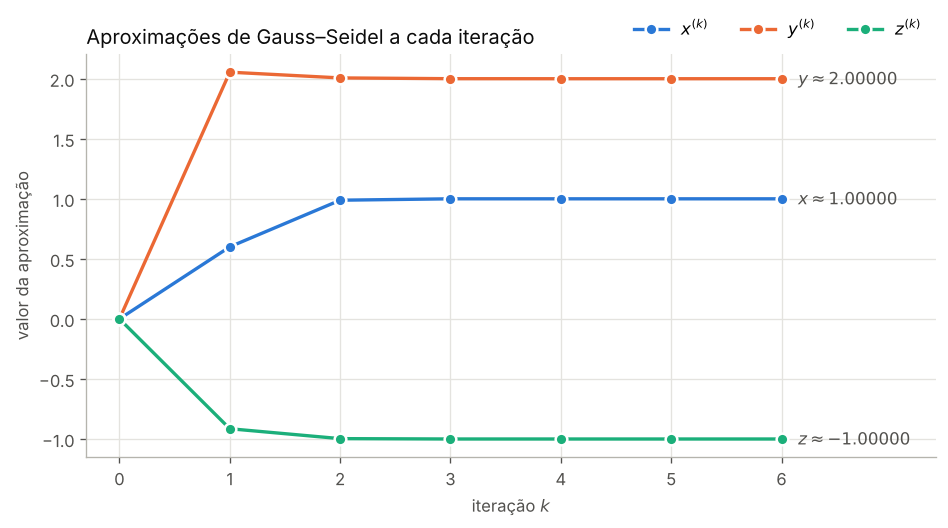

In [8]:
k = tabela["k"]

fig, ax = plt.subplots(figsize=(8, 4.5))
for nome, coluna in [("x", "x(k)"), ("y", "y(k)"), ("z", "z(k)")]:
    ax.plot(k, tabela[coluna], color=CORES[nome], linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5, label=f"${nome}^{{(k)}}$")
    ax.annotate(f"${nome} \\approx {{{tabela[coluna].iloc[-1]:.5f}}}$",
                xy=(k.iloc[-1], tabela[coluna].iloc[-1]), xytext=(10, 0),
                textcoords="offset points", va="center", color=TEXTO)

ax.set_title("Aproximações de Gauss–Seidel a cada iteração", loc="left")
ax.set_xlabel("iteração $k$")
ax.set_ylabel("valor da aproximação")
ax.set_xticks(k)
ax.set_xlim(-0.3, k.iloc[-1] + 1.4)
ax.legend(loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=3)
plt.tight_layout()
plt.show()

### b) Erro entre iterações em escala logarítmica

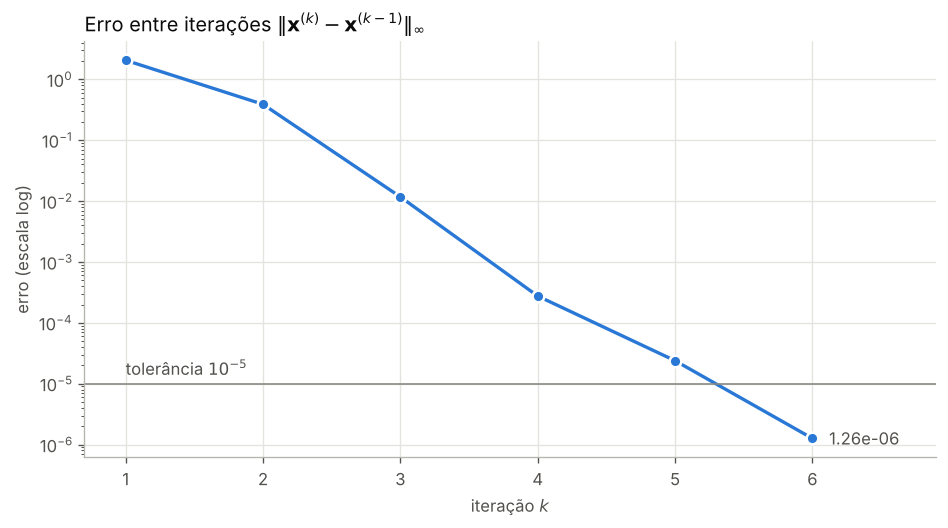

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(k[1:], erros[1:], color=CORES["x"], linewidth=2, marker="o", markersize=7,
            markeredgecolor="white", markeredgewidth=1.5)
ax.axhline(1e-5, color="#8a8983", linewidth=1)
ax.annotate("tolerância $10^{-5}$", xy=(1, 1e-5), xytext=(0, 5),
            textcoords="offset points", color=TEXTO)
ax.annotate(f"{erros[-1]:.2e}", xy=(n_iter, erros[-1]), xytext=(10, 0),
            textcoords="offset points", va="center", color=TEXTO)

ax.set_title(r"Erro entre iterações $\|\mathbf{x}^{(k)} - \mathbf{x}^{(k-1)}\|_\infty$", loc="left")
ax.set_xlabel("iteração $k$")
ax.set_ylabel("erro (escala log)")
ax.set_xticks(k[1:])
ax.set_xlim(0.7, n_iter + 0.9)
plt.tight_layout()
plt.show()

**Análise.** As três componentes se aproximam de $(1, 2, -1)$ já na 3ª iteração e,
a partir daí, as curvas ficam praticamente sobre os valores exatos. No gráfico em escala
logarítmica o erro desce quase em linha reta: cada iteração reduz o erro entre uma e duas
ordens de grandeza (convergência linear rápida), o que é esperado porque $A$ é
estritamente diagonal dominante por linhas, com folga grande entre a diagonal e o resto
de cada linha. O critério $\|\mathbf{x}^{(k)} - \mathbf{x}^{(k-1)}\|_\infty < 10^{-5}$
é satisfeito na iteração $k = 6$.